![image-2.png](attachment:image-2.png)
_Aprendizaje Automático_

_Máster Universitario en Inteligencia Artificial_

# Actividad grupal: Explorando patrones ocultos: Detección de Anomalías en datos
## Objetivos

Mediante este trabajo se pretende que ponga en práctica la aplicación de las técnicas de detección de anomalías. El objetivo es analizar si existen anomalías en el conjunto de datos aplicando técnicas univariantes y multivariantes. Debe detallar los pasos que hay que realizar para detección de valores inusuales.

- 	Entender los métodos media móvil, z-score, Isolation Forest y Local Outlier Factor
- 	Implementar el código para cada una de estas técnicas y analizar si existen o no anomalía
-
	Investigar sobre una técnica de detección de anomalías con un caso de uso concreto.

Descripción de la actividad

Debes realizar la actividad en el Notebook adjunto. Debes ir completando el código solicitado, así como responder a las preguntas que se van realizando.

Tareas que
- alizar
	Detección de
- malías.
	Debes completar el código pedido en este notebook y contestar las pregunt
- finales.
	Buscar dos artículos científicos (https://scholar.google.es/) con un caso de uso de detección de anomalías. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de De
- Learning.
	Para cada artí
- O indicar:
o	Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la detección
-  anomalías.
o	Técnicas de detección de anoma
- s empleadas.
o	Principales resultados de la aplicación y de la investigación.


#### Integrantes del grupo

In [3]:
# Coloca en este espacio el nombre de los integrantes del grupo

**1. Nicolás Gualteros Pérez**

**2. Camilo Linares Villegas**

**3. Esteban Jose Puello Fuentes**

## Detección de anomalías

Los transformadores juegan un papel muy importante en el sistema eléctrico. Aunque son algunos de los componentes más confiables de la red eléctrica, también son propensos a fallar debido a muchos factores, tanto internos como externos. Podría haber muchos iniciadores que causen una falla en el transformador, pero los que potencialmente pueden conducir a una falla catastrófica son los siguientes:
Falla mecánica
Falla dieléctrica

Contenido
Estos datos se recopilaron a través de dispositivos IoT desde el 25 de junio de 2019 hasta el 14 de abril de 2020 y se actualizaron cada 15 minutos.
El dataset contiene 19352 registros.
Descripción de los parámetros:
Voltaje de corriente:
1. VL1- Fase Línea 1
2. VL2- Fase Línea 2
3. VL3- Fase Línea 3
4. IL1- Línea actual 1
5. IL2- Línea actual 2
6. IL3- Línea actual 3
7. VL12- Línea de tensión 1 2
8. VL23- Línea de tensión 2 3
9. VL31- Línea de tensión 3 1
10. INUT-Corriente neutra

In [4]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns

# se carga el dataset, con separados ;, se transforman las dos columnas Date y Time a una única columna con tipo datetime
# en el fichero CSV existen NaN identificados por ?
df = pd.read_csv('muinar07_act3_CurrentVoltage.csv', sep=',')

# imprimir primeras filas para confirmar la correcta carga
print(df.head())

    DeviceTimeStamp    VL1    VL2    VL3  IL1  IL2  IL3  VL12  VL23  VL31  \
0  2019-06-25T13:06    0.0    0.0    0.0  0.0  0.0  0.0   0.0   0.0   0.0   
1  2019-06-27T10:49  238.7  238.7  238.8  0.0  0.0  0.0   0.0   0.0   0.0   
2  2019-06-27T10:51  238.4  238.5  238.5  0.0  0.0  0.0   0.0   0.0   0.0   
3  2019-06-27T10:52  239.9  240.0  240.0  0.0  0.0  0.0   0.0   0.0   0.0   
4  2019-06-27T10:52  239.9  240.0  240.0  0.0  0.0  0.0   0.0   0.0   0.0   

   INUT  
0   0.0  
1   0.0  
2   0.0  
3   0.0  
4   0.0  


#### ¿Cuántas instancias tiene el dataset?

In [5]:
# número de instancias (filas) del dataset
num_instancias = df.shape[0]
num_columnas = df.shape[1]
print("Número de instancias del dataset:", num_instancias)
print("Número de columnas del dataset:", num_columnas)

Número de instancias del dataset: 19352
Número de columnas del dataset: 11


El dataset tiene un total de *19.352* instancias.

Repartidas en *11* Columnas.

#### ¿Cuál es el tipo de datos predominante en las variables?

In [6]:
# mostrar el tipo de datos de cada columna
print(df.dtypes)

print("Tipos de datos presentes:", df.dtypes.unique())

DeviceTimeStamp     object
VL1                float64
VL2                float64
VL3                float64
IL1                float64
IL2                float64
IL3                float64
VL12               float64
VL23               float64
VL31               float64
INUT               float64
dtype: object
Tipos de datos presentes: [dtype('O') dtype('float64')]


El tipo de datos predominante en las variables es float64, ya que casi todas las columnas numéricas están en formato decimal.

## Variables nulas

#### ¿Tiene este dataset datos faltantes?

In [7]:
# comprobar si existen valores faltantes en el dataset
num_null = df.isnull().sum()

print("Valores nulos por columna:\n")
print(num_null)

# comprobación global
print("\nTotal de nulos en el dataset:", df.isnull().sum().sum())


Valores nulos por columna:

DeviceTimeStamp    0
VL1                0
VL2                0
VL3                0
IL1                0
IL2                0
IL3                0
VL12               0
VL23               0
VL31               0
INUT               0
dtype: int64

Total de nulos en el dataset: 0


El dataset no contiene valores nulos. Todas las columnas presentan 0 nulos, por lo que se puede trabajar directamente con las técnicas de detección de anomalías sin necesidad de imputación o limpieza adicional.

#### Matriz de correlación entre variables numéricas.

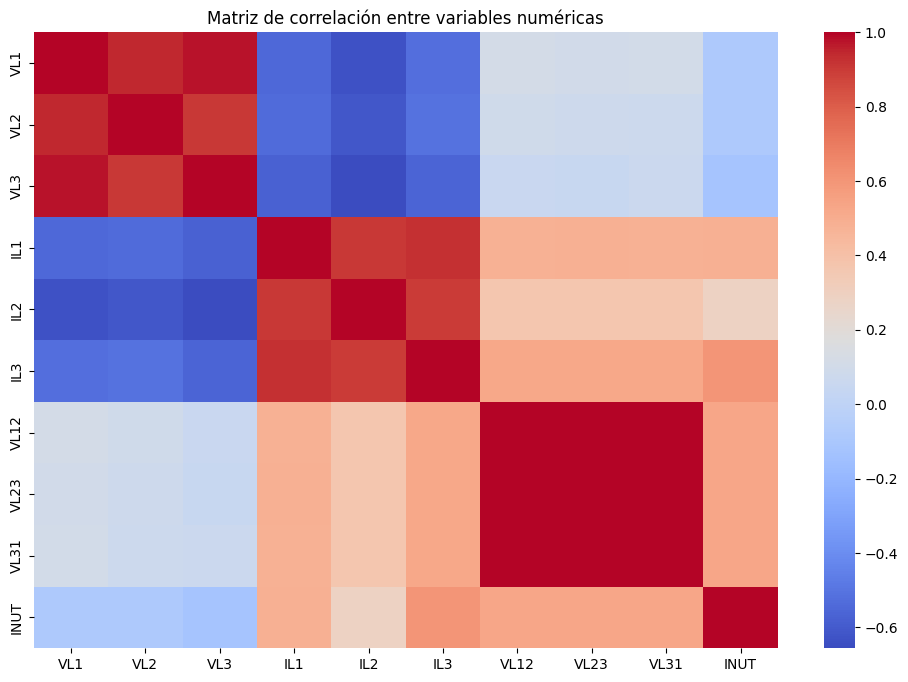

In [8]:
# matriz de correlación entre todas las variables numéricas

df_num = df.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(12, 8))
sns.heatmap(df_num.corr(), annot=False, cmap='coolwarm')
plt.title('Matriz de correlación entre variables numéricas')
plt.show()



La matriz de correlación muestra que los voltajes trifásicos (VL1, VL2, VL3) están fuertemente correlacionados entre sí, al igual que las corrientes (IL1, IL2, IL3), lo cual es coherente con el comportamiento esperado en un sistema eléctrico trifásico. También se observan correlaciones negativas entre algunos voltajes y corrientes, indicando relaciones inversas propias de variaciones en la carga. Las tensiones compuestas (VL12, VL23, VL31) presentan correlaciones intermedias con ambos grupos, mientras que la variable INUT aporta información adicional sin correlaciones extremas. En conjunto, estas relaciones confirman que el dataset es estructurado y adecuado para aplicar técnicas de detección de anomalías tanto univariadas como multivariadas.

#### Estadísticas

In [9]:
estadisticas = df.describe().T
print(estadisticas)

        count        mean         std  min      25%    50%    75%    max
VL1   19352.0  241.068019    9.536380  0.0  235.400  242.7  247.5  261.2
VL2   19352.0  240.515456    9.801129  0.0  235.100  242.1  246.7  261.3
VL3   19352.0  239.912293    8.846213  0.0  235.100  241.1  245.3  261.3
IL1   19352.0   73.710857   41.256800  0.0   46.775   69.5  100.1  224.1
IL2   19352.0   58.970592   40.463867  0.0   31.500   50.2   82.5  253.6
IL3   19352.0   83.226555   43.609360  0.0   56.300   80.2  113.9  247.3
VL12  19352.0  379.475300  119.963080  0.0  400.700  417.8  427.5  446.5
VL23  19352.0  378.526261  119.417113  0.0  401.300  416.3  425.3  444.8
VL31  19352.0  379.969311  120.074752  0.0  401.900  417.9  427.6  447.3
INUT  19352.0   26.315187   15.103268  0.0   16.800   25.6   35.7  145.8


Al revisar las estadísticas se ve que los voltajes (VL1, VL2 y VL3) se mantienen bastante estables, con valores similares entre ellos. Las corrientes (IL1, IL2 y IL3) sí muestran más variación, lo cual es normal porque cambian según la carga. Las tensiones compuestas y la variable INUT también tienen rangos más amplios, lo que indica que no siempre se comportan igual. En general, los datos no muestran valores raros o fuera de lugar, así que esta tabla sirve como una buena referencia antes de aplicar las técnicas de detección de anomalías.

/tmp/ipython-input-2295662418.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['INUT'])


<Axes: xlabel='INUT', ylabel='Density'>

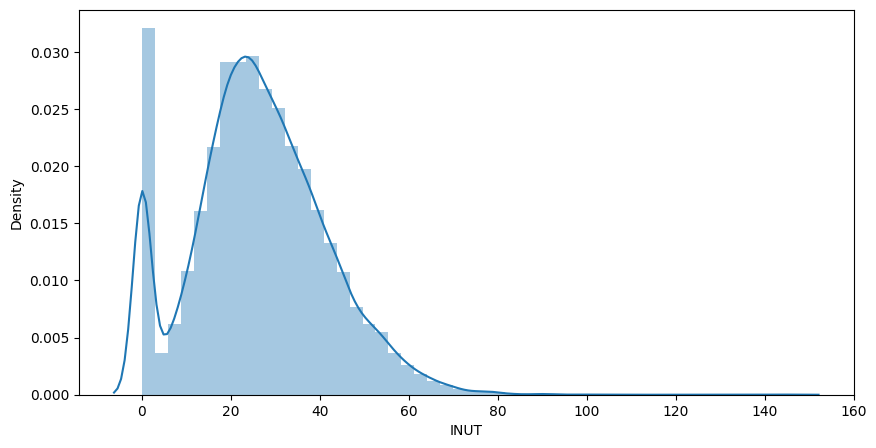

In [10]:
# vamos a observar la variable INUT
plt.figure(figsize = (10,5))
sns.distplot(df['INUT'])

Al observar la distribución de la variable INUT se nota que no sigue una forma totalmente uniforme. Tiene un pico muy pronunciado cerca de cero y luego una parte más amplia donde los valores se concentran entre 20 y 60. Después de eso, los valores empiezan a disminuir bastante rápido y casi no hay registros muy altos. Esto sugiere que INUT normalmente se mueve dentro de un rango estable, pero también puede tener momentos puntuales donde se dispara o cae demasiado, lo cual podría ser relevante a la hora de detectar anomalías más adelante.

#### ¿Es necesario hacer algún tratamiendo adicional sobre los datos?

In [11]:
### PON AQUÍ TU CÓDIGO EN CASO DE QUE SEA NECESARIO HACER ALGÚN TRATAMIENTO ADICIONAL

No es necesario realizar un tratamiento adicional sobre los datos, ya que el dataset no presenta valores nulos y todas las variables están correctamente tipadas. Además, la columna temporal ya fue convertida a formato datetime y establecida como índice, por lo que los datos están listos para aplicar las técnicas de detección de anomalías.

#### Media móvil

In [12]:
# Vamos a aplicar la técnica de detección de anomalías de Media Móvil sobre la variable INUT

In [13]:
# selección de la variable INUT
serie_mm = df['INUT']

# definición del tamaño de la ventana
window_size = 20

In [14]:
# Calcula la media móvil

In [15]:
# calcular la media móvil
rolling_mean = serie_mm.rolling(window=window_size).mean()

# calcular la desviación estándar móvil
rolling_std = serie_mm.rolling(window=window_size).std()

In [16]:
# Define un umbral para detectar anomalías

In [17]:
# definición de umbral
threshold = 2

# identificación de anomalías
anomalies = serie_mm[(serie_mm - rolling_mean).abs() > threshold * rolling_std]

In [18]:
# Visualiza los resultados

Anomalías detectadas: 1126


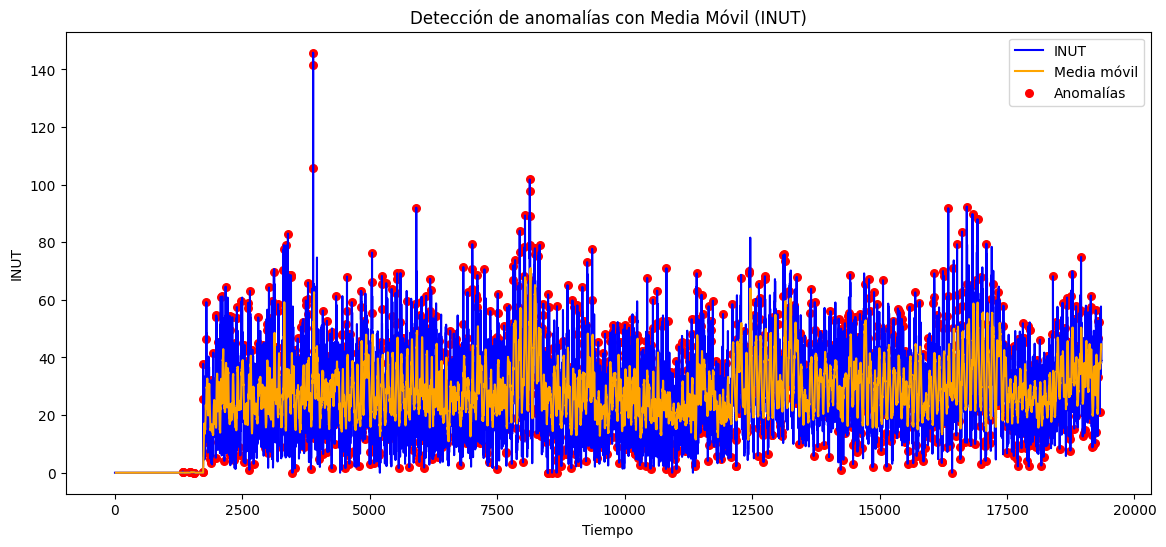

In [19]:
# mostrar cuántas anomalías detectó
print(f"Anomalías detectadas: {len(anomalies)}")

# gráfica
plt.figure(figsize=(14, 6))
plt.plot(serie_mm, label='INUT', color='blue')
plt.plot(rolling_mean, label='Media móvil', color='orange')

# marcación de anomalías
plt.scatter(anomalies.index, anomalies.values, color='red', label='Anomalías', s=30)

plt.title('Detección de anomalías con Media Móvil (INUT)')
plt.xlabel('Tiempo')
plt.ylabel('INUT')
plt.legend()
plt.show()

Al aplicar la media móvil sobre la variable INUT se observan muchos puntos que se alejan bastante del comportamiento promedio de la serie, y por eso el método detecta un número alto de anomalías. Esto tiene sentido porque INUT es una señal muy variable y con picos frecuentes, así que cualquier subida o bajada fuerte respecto a la media se marca como valor inusual. En general, el resultado ayuda a identificar los momentos donde la señal se comporta de forma más extrema, aunque también es posible que algunos de estos “picos” no sean fallos reales sino simplemente parte del funcionamiento normal del sistema.

#### Z-Score

In [20]:
# Vamos a aplicar la técnica de detección de anomalías Z-Score
# Pon aquí tu código

In [21]:
# técnica de detección de anomalías Z-Score
from scipy import stats

# selección la variable INUT
serie_zscore = df['INUT']

# calcular el z-score para cada punto
z_scores = stats.zscore(serie_zscore)


In [22]:
# Define un umbral para detectar anomalías (por ejemplo, 3 desviaciones estándar)

In [23]:
# definición de umbral
threshold = 3

# identificación anomalías: valores cuyo |z| es mayor que 3
anomalies_z = serie_zscore[abs(z_scores) > threshold]

print("Número de anomalías detectadas:", len(anomalies_z))


Número de anomalías detectadas: 72


In [24]:
# Visualiza los resultados

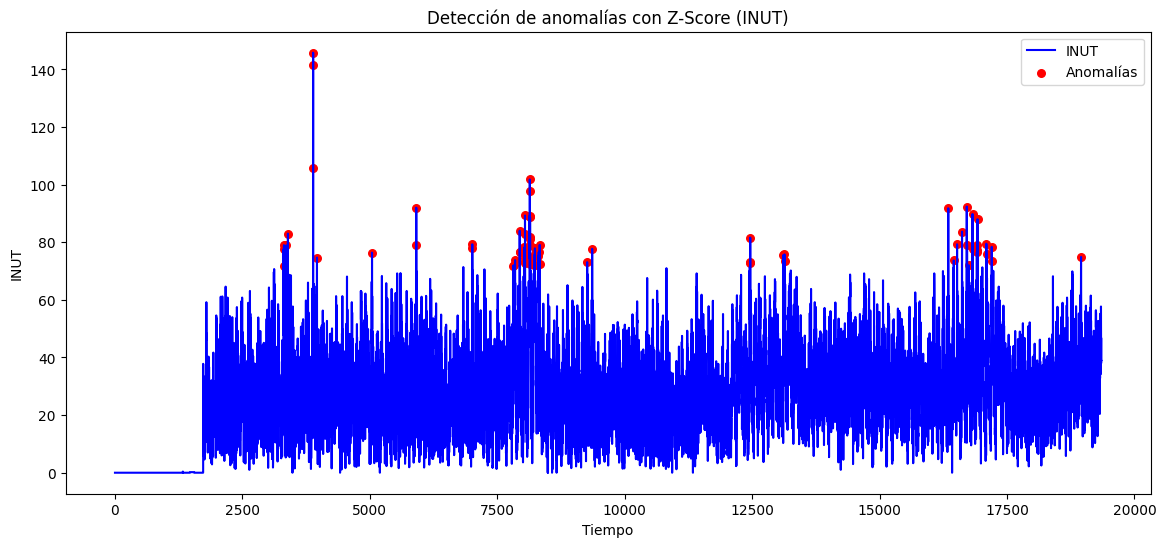

In [25]:
plt.figure(figsize=(14, 6))
plt.plot(serie_zscore, label='INUT', color='blue')
plt.scatter(anomalies_z.index, anomalies_z.values, color='red', label='Anomalías', s=30)
plt.title('Detección de anomalías con Z-Score (INUT)')
plt.xlabel('Tiempo')
plt.ylabel('INUT')
plt.legend()
plt.show()


Al aplicar Z-Score sobre la variable INUT, el método detectó muchos menos puntos anómalos que la media móvil. Esto tiene sentido porque Z-Score solo marca como anomalía los valores que realmente se salen de la distribución normal del conjunto, es decir, los picos más extremos. En general, los puntos detectados coinciden con momentos donde INUT tiene subidas muy fuertes respecto a su valor habitual. El resultado me permite ver qué tan “extraños” son esos valores dentro del comportamiento total de la serie.

#### Isolation Forest

In [26]:
from sklearn.ensemble import IsolationForest

# seleccionar la variable INUT para Isolation Forest
X_if = df[['INUT']]

# inicializar el modelo Isolation Forest con contamination al 5%
iso_forest_5 = IsolationForest(contamination=0.05, random_state=42)

# ajustar el modelo y predecir anomalías
df['anomaly_if_5'] = iso_forest_5.fit_predict(X_if)

# los valores -1 indican anomalías, 1 indican valores normales
# para facilitar el análisis, podemos mapear -1 a 'Anomalía' y 1 a 'Normal'
df['anomaly_label_if_5'] = df['anomaly_if_5'].apply(lambda x: 'Anomalía' if x == -1 else 'Normal')

# Obtener los scores de anomalía
df['anomaly_score_if_5'] = iso_forest_5.decision_function(X_if)

print(f"Anomalías detectadas con Isolation Forest (5%): {len(df[df['anomaly_if_5'] == -1])}")

Anomalías detectadas con Isolation Forest (5%): 963


In [27]:
# Las columnas de puntaje y si el dato es anómalo o no ya fueron agregadas al DataFrame 'df'
# con los nombres 'anomaly_if_5', 'anomaly_label_if_5' y 'anomaly_score_if_5' en el paso anterior.

/tmp/ipython-input-3417170943.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='anomaly_label_if_5', data=df, palette={'Normal':'blue', 'Anomalía':'red'})


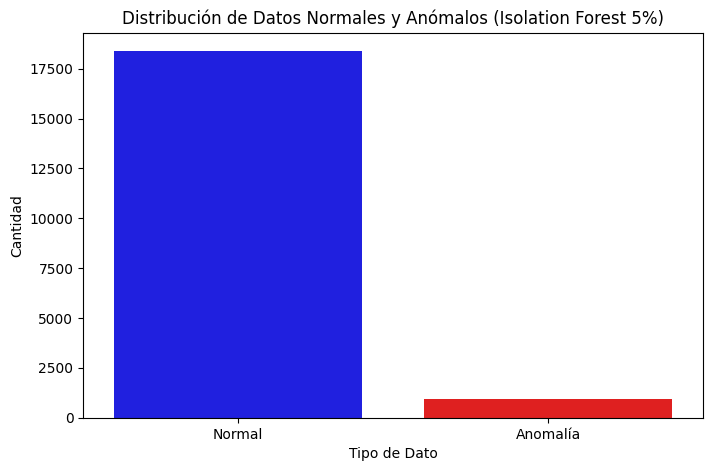

In [28]:
# Crea un gráfico de barras para mostrar los datos anómalos vs los datos normales
plt.figure(figsize=(8, 5))
sns.countplot(x='anomaly_label_if_5', data=df, palette={'Normal':'blue', 'Anomalía':'red'})
plt.title('Distribución de Datos Normales y Anómalos (Isolation Forest 5%)')
plt.xlabel('Tipo de Dato')
plt.ylabel('Cantidad')
plt.show()

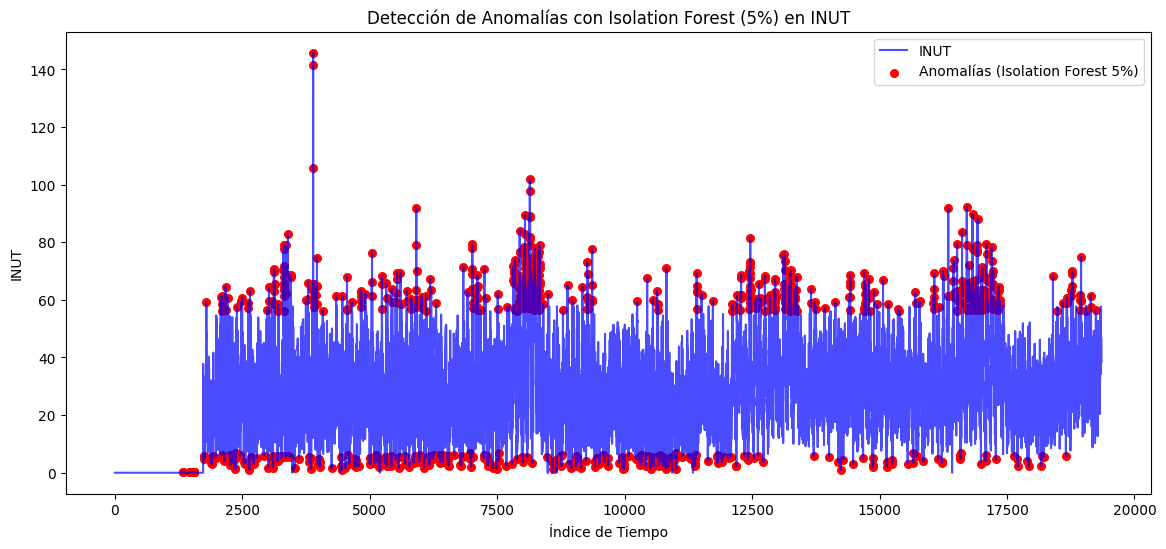

In [29]:
# Crea un gráfico donde se puedan ver los datos anómalos sobre la variable INUT.
plt.figure(figsize=(14, 6))
plt.plot(df['INUT'], label='INUT', color='blue', alpha=0.7)
anomalies_data = df[df['anomaly_if_5'] == -1]
plt.scatter(anomalies_data.index, anomalies_data['INUT'], color='red', label='Anomalías (Isolation Forest 5%)', s=30)
plt.title('Detección de Anomalías con Isolation Forest (5%) en INUT')
plt.xlabel('Índice de Tiempo')
plt.ylabel('INUT')
plt.legend()
plt.show()

Anomalías detectadas con Isolation Forest (1%): 189


/tmp/ipython-input-495100917.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='anomaly_label_if_1', data=df, palette={'Normal':'blue', 'Anomalía':'red'})


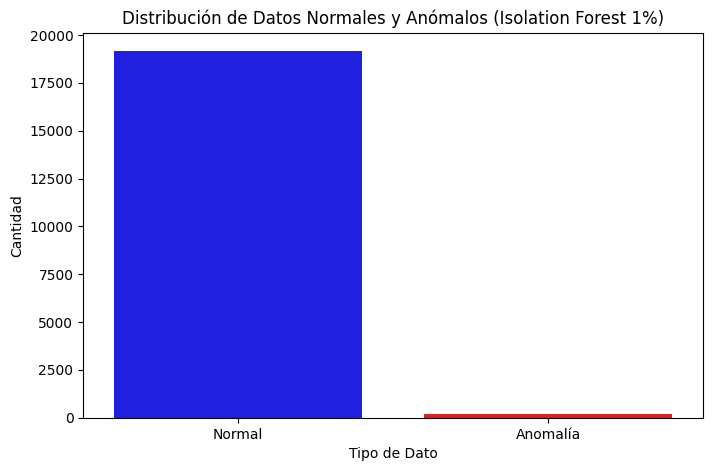

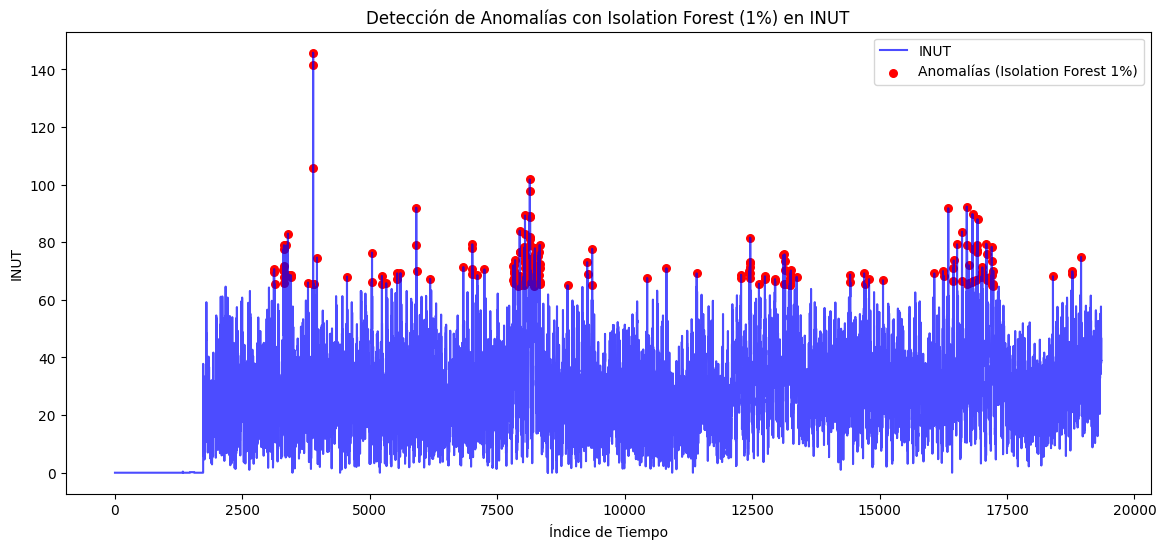

In [30]:
# Repite los pasos anteriores con el parámetro de contamination en 1%

# seleccionar la variable INUT para Isolation Forest
X_if = df[['INUT']]

# inicializar el modelo Isolation Forest con contamination al 1%
iso_forest_1 = IsolationForest(contamination=0.01, random_state=42)

# ajustar el modelo y predecir anomalías
df['anomaly_if_1'] = iso_forest_1.fit_predict(X_if)

# los valores -1 indican anomalías, 1 indican valores normales
df['anomaly_label_if_1'] = df['anomaly_if_1'].apply(lambda x: 'Anomalía' if x == -1 else 'Normal')

# Obtener los scores de anomalía
df['anomaly_score_if_1'] = iso_forest_1.decision_function(X_if)

print(f"Anomalías detectadas con Isolation Forest (1%): {len(df[df['anomaly_if_1'] == -1])}")

plt.figure(figsize=(8, 5))
sns.countplot(x='anomaly_label_if_1', data=df, palette={'Normal':'blue', 'Anomalía':'red'})
plt.title('Distribución de Datos Normales y Anómalos (Isolation Forest 1%)')
plt.xlabel('Tipo de Dato')
plt.ylabel('Cantidad')
plt.show()

plt.figure(figsize=(14, 6))
plt.plot(df['INUT'], label='INUT', color='blue', alpha=0.7)
anomalies_data_1 = df[df['anomaly_if_1'] == -1]
plt.scatter(anomalies_data_1.index, anomalies_data_1['INUT'], color='red', label='Anomalías (Isolation Forest 1%)', s=30)
plt.title('Detección de Anomalías con Isolation Forest (1%) en INUT')
plt.xlabel('Índice de Tiempo')
plt.ylabel('INUT')
plt.legend()
plt.show()

Al aplicar Isolation Forest sobre la variable INUT, el modelo logró identificar de forma más equilibrada los puntos que se alejan del comportamiento general de la serie. Con una contaminación del 5% se detectaron bastantes valores inusuales, mientras que al bajarla al 1% el método se volvió más estricto y solo marcó los casos realmente extremos. Me parece útil porque, a diferencia de los métodos univariados, aquí el algoritmo aprende directamente del patrón completo de la señal y resalta los momentos donde INUT se comporta de forma claramente distinta al resto. Visualmente, las anomalías coinciden con los picos más fuertes, lo cual tiene sentido para este tipo de dato.

## Local Outlier Factor

In [31]:
# Vamos a aplicar la técnica de detección de anomalías de Local Outlier Factor
# Pon aquí tu código

In [32]:
from sklearn.neighbors import LocalOutlierFactor

X = df[['INUT']]

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    metric='euclidean',
    novelty=False
)

# LOF valores -1 indican anomalías, 1 indican valores normales
labels = lof.fit_predict(X)

df["lof_score"] = lof.negative_outlier_factor_
df["lof_anomaly"] = (labels == -1).astype(int)

/usr/local/lib/python3.12/dist-packages/sklearn/neighbors/_lof.py:322: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


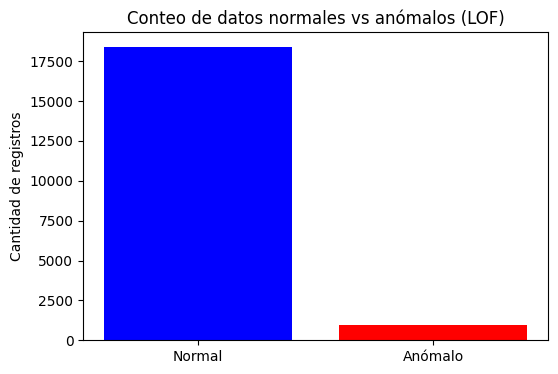

In [33]:
counts = df["lof_anomaly"].value_counts().sort_index()

plt.figure(figsize=(6,4))
plt.bar(["Normal", "Anómalo"], counts, color=["blue", "red"])
plt.title("Conteo de datos normales vs anómalos (LOF)")
plt.ylabel("Cantidad de registros")
plt.show()

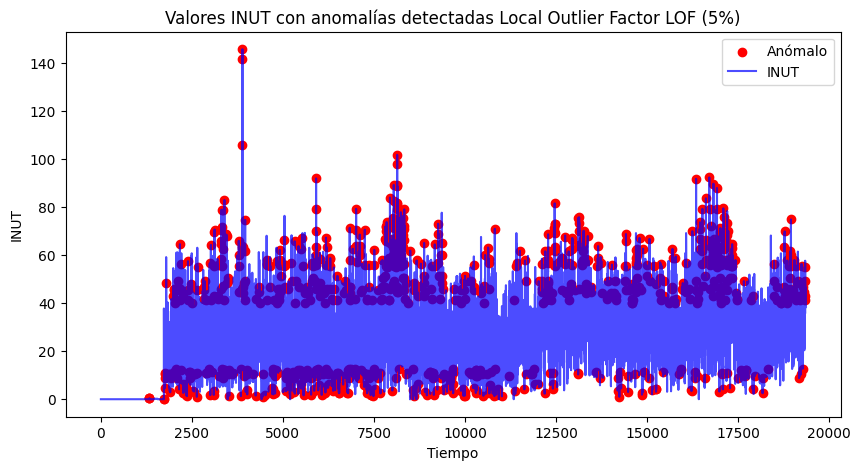

In [34]:
plt.figure(figsize=(10,5))

idx = np.arange(len(df))
normales = df["lof_anomaly"] == 0
anomalos = df["lof_anomaly"] == 1

# Puntos anómalos
plt.scatter(idx[anomalos], df.loc[anomalos, "INUT"],
            label="Anómalo", color="red")
# Puntos normales
plt.plot(df['INUT'], label='INUT', color='blue', alpha=0.7)

plt.title("Valores INUT con anomalías detectadas Local Outlier Factor LOF (5%)")
plt.xlabel("Tiempo")
plt.ylabel("INUT")
plt.legend()
plt.show()


LocalOutlierFactor (LOF) mide la densidad local de un punto usando sus k vecinos más cercanos. Si la densidad de ese punto es significativamente menor que la de sus vecinos, se considera un dato atípico (outlier). Con el parámetro *contamination* se asigna el porcentaje de anómalos que se encuentran.

Con un 5% de contaminación, el algoritmo logra capturar algunos picos, pero también introduce una proporción importante de falsos positivos dentro de la franja "normal", este comportamiento se debe a la naturaleza del mismo.

Dentro del rango "normal", detecta puntos rojos porque su vecindario es estadísticamente distinto aunque el valor no es extremo, además LOF no busca valores grandes o pequeños, sino densidad rara. Debido a esto, LOF no es adecuado como detector de picos en una serie univariada porque aunque los picos sean extremos globales, no son anomalías locales según la lógica de densidad usada por LOF.


## Análisis

In [35]:
# Realiza un análisis detallado de los resultados obtenidos en cada una de las técnicas aplicadas. Utiliza gráficos o trablas para apoyar tu conclusiones

Después de probar los cuatro métodos de detección de anomalías sobre la variable INUT, se nota que cada técnica identifica diferentes tipos de comportamientos inusuales y que no existe un único método “correcto”, sino que todos aportan una mirada distinta sobre la misma señal.

La media móvil fue el método que más anomalías detectó. Esto tiene sentido porque INUT es una señal muy fluctuante y cualquier desviación fuerte respecto a la media local la marca como punto extraño. Esto hace que el método sea muy sensible, pero también que capture situaciones que quizás forman parte del comportamiento normal del sistema.

Con Z-Score, el número de anomalías bajó bastante. Este método solo resalta los valores que realmente se salen de la distribución general, es decir, los picos más extremos. Por eso los resultados son más “limpios” y dejan ver únicamente los momentos donde INUT se aleja mucho del rango típico.

En el caso de Isolation Forest, el resultado depende del parámetro de contaminación. Con el 5% detectó bastantes puntos inusuales, pero con el 1% se volvió más estricto y se quedó solo con los casos más claros. Me pareció un método más equilibrado, porque aprende de la forma completa de la serie y no solo de valores puntuales.

Por último, Local Outlier Factor (LOF) también detectó anomalías, pero a veces marca puntos dentro del rango normal simplemente porque su densidad local es distinta. Esto puede ser útil si uno quiere analizar comportamientos “raros” en términos de estructura, no solo de magnitud, aunque también puede generar más falsos positivos.

En general, los cuatro métodos coinciden en resaltar los picos más marcados de INUT, pero cada uno lo hace desde una lógica distinta. Media móvil es el más sensible, Z-Score el más estricto, Isolation Forest el más balanceado y LOF el que mejor captura rarezas locales. Usarlos en conjunto permite tener una visión mucho más completa del comportamiento anómalo de la señal.

## Tabla comparativa de los métodos de detección de anomalías

| **Método** | **Cómo funciona** | **Cantidad de anomalías detectadas** | **Comportamiento observado en INUT** |
|-----------|--------------------|---------------------------------------|---------------------------------------|
| **Media Móvil** | Compara cada punto con la media y la desviación estándar de una ventana local. | **1126** | Detectó casi todos los picos y variaciones fuertes; es el método más sensible. |
| **Z-Score** | Calcula cuántas desviaciones estándar se aleja cada valor de la media global. | **72** | Resaltó únicamente los picos más extremos y valores claramente fuera del rango típico. |
| **Isolation Forest (5%)** | Aísla puntos mediante divisiones aleatorias; los más fáciles de separar son anomalías. | **963** | Marcó muchos valores elevados y también variaciones intermedias. |
| **Isolation Forest (1%)** | Igual que el anterior, pero con menor proporción de anomalías esperadas. | **189** | Señaló principalmente los picos más fuertes, de forma más estricta que el modelo al 5%. |
| **Local Outlier Factor (LOF)** | Compara la densidad local de cada punto con la de sus vecinos cercanos. | **≈5% del total** | Detectó picos y también puntos dentro del rango normal cuya densidad era distinta. |


#### Conclusión

Después de aplicar las distintas técnicas de detección de anomalías sobre la variable INUT, quedó claro que cada método ofrece una perspectiva diferente del comportamiento de la señal. La media móvil fue la más sensible y detectó prácticamente todos los cambios bruscos; Z-Score se enfocó solo en los picos más extremos; Isolation Forest ofreció un equilibrio interesante dependiendo del nivel de contaminación; y LOF resaltó tanto picos como puntos que se comportaban de forma inusual respecto a sus vecinos.

En conjunto, los resultados muestran que INUT es una señal bastante variable y con numerosos momentos que pueden considerarse atípicos según el método utilizado. No existe una única técnica “correcta”, sino que combinarlas ayuda a entender mejor qué tipos de anomalías aparecen y en qué situaciones se producen. Este análisis conjunto permite tener una visión más completa y confiable del comportamiento real del sistema.

## Artículos de investigación

#### Artículo 1

A Comparative Analysis of Machine Learning Techniques for IoT Intrusion Detection

João Vitorino, Rui Andrade, Isabel Praça, Orlando Sousa, Eva Maia

2021

https://arxiv.org/pdf/2111.13149

**Resumen:**

La investigación trata sobre los desafíos de seguridad que presentan los sistemas Internet of Things (IoT), los cuales son vulnerables debido a sus limitaciones de hardware, protocolos débiles y exposición a ciberataques. Con el aumento de malware, es una parte fundamental contar con mecanismos confiables para detectar comportamientos anómalos en el tráfico de red IoT.

Para abordar este reto, el estudio analiza y compara tres familias de técnicas de aprendizaje automático aplicadas a detección de anomalías utilizando el dataset IoT-23, el cual consiste en 23 capturas etiquetadas de flujos de red maliciosos y benignos, causados por ataques de malware dirigidos a dispositivos IoT entre 2018 y 2019. Este es un conjunto de datos valioso, ya que revela patrones reales del tráfico de la red IoT y proporciona una gran cantidad de flujos maliciosos etiquetados. Los métodos usados fueron:

- *Modelos supervisados:* SVM, XGBoost y LightGBM.

- *Modelos no supervisados de detección de anomalías:* Isolation Forest (iForest) y Local Outlier Factor (LOF).

- *Aprendizaje por refuerzo profundo:* Modelo basado en Double Deep Q-Network (DDQN).

**Objetivo:**

El objetivo general es comparar técnicas de aprendizaje automático supervisadas, no supervisadas y de aprendizaje por refuerzo para la detección de anomalías en sistemas IoT, utilizando varios subconjuntos del dataset IoT-23.

Esto surge como respuesta al problema de seguridad en IoT:

- Los dispositivos IoT tienen vulnerabilidades de software y hardware, protocolos débiles y poca capacidad de defensa.

- Crecimiento acelerado de malware y ciberataques, como Mirai, Torii o ataques tipo botnet.

- Pueden haber 2 tipos de ataques: Ataques pasivos (espionaje, análisis de tráfico) o activos (DoS, brute-force, man-in-the-middle).

Por lo tanto, el estudio busca determinar qué técnicas son más eficientes para detectar tráfico malicioso en escenarios reales de IoT, tanto para clasificación binaria (benigno/malicioso) como para multi-clase (identificar tipo de ataque). Para ello se aplicó un proceso de preprocesamiento, validación cruzada y evaluación independiente utilizando la métrica F1-score, adecuada para datasets desbalanceados.

**Técnicas de detección de anomalías empleadas:**

***A. Modelos supervisados***

Estos clasifican tráfico con etiquetas:

- SVM
- XGBoost
- LightGBM

Son modelos predictivos tradicionales, no estrictamente detectores de anomalías, pero sí usados para clasificación.

***B. Modelos no supervisados***

Aquí se encuentran los detectores de anomalías aplicados sin etiquetas:

**Isolation Forest (iForest):**

Detecta anomalías aislando observaciones que requieren pocas divisiones para separarse del resto.


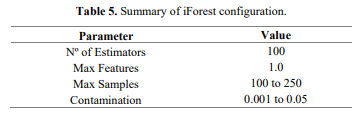

**Local Outlier Factor (LOF):**

Detecta anomalías comparando densidad local con vecinos. Utiliza Euclidean metric, KD-Tree, y vecinos entre 35 y 520 según tamaño del dataset.

Ambos modelos fueron aplicados como one-class classifiers, entrenándose solo con tráfico normal para identificar ataques desconocidos.


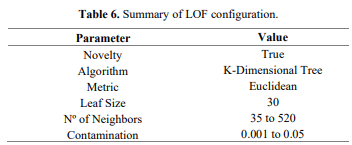


***C. Aprendizaje por refuerzo profundo (DRL)***

Se usa un Double Deep Q-Network (DDQN) adaptado a detección de intrusiones. Este modelo aprende continuamente mediante un sistema de recompensas por clasificación correcta.

**Resultados:**

***A. Resultados en clasificación binaria***

*Supervisados (SVM, XGBoost, LightGBM)*

Obtuvo F1-scores cercanos al 100% en casi todos los datasets grandes.
LightGBM mostró la mejor generalización:

*Isolation Forest*

- En datasets grandes fue inferior a los supervisados.

- En datasets pequeños o desbalanceados obtuvo resultados muy buenos (incluso 100% en algunos casos).

Este método logró un buen rendimiento general, muy adecuado para la detección de anomalías cuando se entrena con conjuntos de datos más pequeños y desequilibrados. Isolation Forest es útil cuando el volumen de datos normales es mucho mayor que el de anomalías.

*Local Outlier Factor*

- Peor desempeño que iForest.

- Funciona relativamente bien en datasets pequeños, pero falla en los grandes.

*Aprendizaje por Refuerzo (DRL)*

- Se acerca al rendimiento de los supervisados cuando hay muchos datos.

- Su rendimiento cae significativamente con datasets pequeños.

El modelo DRL casi alcanzó los resultados de los modelos supervisados en los conjuntos más grandes, sin embargo se requiere una gran cantidad de datos.



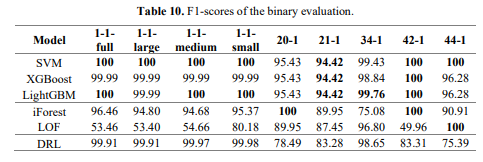

***B. Resultados en clasificación multi-clase (tipo de ataque)***

Los obstáculos siguen siendo la falta de datos de formación y las clases subrepresentadas.

- LightGBM fue nuevamente el mejor modelo.

- Todos los métodos supervisados tuvieron dificultades cuando había clases con muy pocos ejemplos.

- Los métodos no supervisados no pueden utilizarse aquí, pues no realizan clasificación multi-clase (solo detectan anomalías).

- DRL tuvo problemas aún mayores en multi-clase.







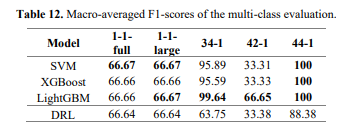

Los resultados muestran que los modelos supervisados obtienen el mejor rendimiento general, alcanzando valores cercanos al 100% en varios conjuntos de datos. LightGBM destaca como el modelo más robusto y con mejor capacidad de generalización.

Por otro lado, los modelos no supervisados presentan un rendimiento menor en datasets grandes, pero son especialmente eficaces para detectar ataques muy poco frecuentes, siendo iForest el mejor en este grupo.

El modelo de aprendizaje por refuerzo (DRL) logra aproximarse al rendimiento de los supervisados en conjuntos de datos grandes y demuestra potencial para adaptarse a cambios en patrones de tráfico, aunque requiere más datos para ser estable.

**Conclusiones:**

Los modelos supervisados obtuvieron el rendimiento más fiable en ambos escenarios, alcanzando puntuaciones más altas al entrenarse con un mayor número de ejemplos de ataques de malware. LightGBM destacó por mostrar la mejor generalización a varios conjuntos de evaluación, especialmente en el escenario multiclase.

A pesar de los resultados significativamente inferiores de los modelos no supervisados, estos parecen ser ventajosos para la detección de ataques de malware de muy baja frecuencia. Además, iForest logró un buen rendimiento general, lo que destaca su idoneidad para la detección de anomalías al entrenarse con conjuntos de datos más pequeños y desequilibrados.

En el futuro, estos tres tipos distintos de técnicas de aprendizaje automático podrán combinarse para potenciar sus ventajas y superar sus inconvenientes individuales.

#### Artículo 2

# Articulo

"AN EFFICIENT ONE-CLASS SVM FOR ANOMALY DETECTION IN THE INTERNET OF THINGS" (Una SVM de Una Clase Eficiente para la Detección de Anomalías en el Internet de las Cosas)


## Objetivo (Problema Real)
El objetivo principal de la investigación es desarrollar un método rápido, eficiente y preciso para la detección de comportamientos anómalos o novedosos (novelty detection) en dispositivos del Internet de las Cosas (IoT).


La detección de anomalías se aplica a:

- Ciberseguridad en IoT: Abordar la amenaza significativa que suponen los dispositivos IoT inseguros para la infraestructura crítica y la Internet en general.
- Identificación de Amenazas: Detectar una amplia clase de eventos, actividades o dispositivos novedosos, incluyendo actividad maliciosa (p. ej., de dispositivos infectados), fallos físicos de dispositivos, la introducción de dispositivos no autorizados (rogue devices) o incidentes de seguridad física.
- Restricciones de Recursos: Superar las limitaciones de memoria y computacionales que hacen que las técnicas tradicionales de OCSVM sean inviables para el despliegue práctico en dispositivos IoT con recursos limitados, como routers domésticos o sensores integrados.


## Técnicas de Detección de Anomalías Empleadas

El enfoque se basa en técnicas de aprendizaje automático no supervisado/semisupervisado (no-Deep Learning):
- Máquina de Vectores de Soporte de Una Clase (One-Class Support Vector Machine - OCSVM): Es el enfoque base y una de las técnicas más avanzadas para la detección de novedades o anomalías, gracias a su flexibilidad para ajustar límites no lineales complejos entre datos normales y novedosos.
- Optimización OCSVM: Se utilizan extensiones llamadas Nyström y (Gaussian) Sketching (específicamente Kernel Johnson-Linderstrauss - KJL) para aproximar la matriz kernel y mapear los datos a un espacio de menor dimensión. Esto se hace para reducir drásticamente los requisitos de memoria y el tiempo de predicción.
- Modelado de Densidad: Los enfoques optimizados (OC-Nyström y OC-KJL) se combinan con Modelos de Mezcla Gaussiana (Gaussian Mixture Models - GMM) para modelar de manera eficiente los clusters de tráfico normal en el espacio de características proyectado, utilizando una simple regla de detección basada en niveles de densidad.



Principales Resultados de la Aplicación y de la Investigación
Los métodos propuestos (OC-Nyström y OC-KJL) demostraron mejoras significativas en eficiencia y rendimiento en conjuntos de datos de tráfico IoT:


- Reducción de Tiempo de Detección: Se observaron mejoras típicas en la velocidad de detección de entre 14 y 20 veces en comparación con el OCSVM de referencia, alcanzando hasta 40 veces o más en algunos conjuntos de datos.
- Reducción de Espacio (Memoria): La complejidad espacial se redujo por factores de 20 o más en comparación con el modelo OCSVM original. Esta reducción de espacio es clave para la implementación práctica en dispositivos IoT con recursos restringidos.
- Rendimiento Mantenido/Mejorado: Tras una calibración adecuada, los enfoques OC-Nyström y OC-KJL lograron un rendimiento de detección a la par o incluso ligeramente superior (medido por el AUC - Area Under the Curve) al OCSVM de referencia. Esto sugiere que las optimizaciones no solo aumentan la velocidad, sino que en algunos casos, el mapeo a menor dimensión puede ayudar a recuperar estructuras intrínsecas en los datos